In [1]:
#!cd mask_rcnn/

In [2]:
import sys
sys.path.append('mask_rcnn')

In [18]:
import os
import sys
import random
import math
import re
import time
import numpy as np
import cv2
import matplotlib
import skimage.draw
import json
import matplotlib.pyplot as plt

# Root directory of the project
ROOT_DIR = os.path.abspath("mask_rcnn")

# Import Mask RCNN
sys.path.append(ROOT_DIR)  # To find local version of the library
from mrcnn.config import Config
from mrcnn import utils
import mrcnn.model as modellib
from mrcnn import visualize
from mrcnn.model import log

%matplotlib inline 

# Directory to save logs and trained model
#MODEL_DIR = os.path.join(ROOT_DIR, "logs")
MODEL_DIR = os.path.join('/home/user/Desktop/Projects/adevi_cnn3/mask_rcnn/logs')
# Local path to trained weights file
#COCO_MODEL_PATH = os.path.join(ROOT_DIR, "mask_rcnn_coco.h5")
COCO_MODEL_PATH = os.path.join('.', "mask_rcnn_coco.h5")
# Download COCO trained weights from Releases if needed
if not os.path.exists(COCO_MODEL_PATH):
    utils.download_trained_weights(COCO_MODEL_PATH)

# Mask R-CNN - Train on Shapes Dataset


This notebook shows how to train Mask R-CNN on your own dataset. To keep things simple we use a synthetic dataset of shapes (squares, triangles, and circles) which enables fast training. You'd still need a GPU, though, because the network backbone is a Resnet101, which would be too slow to train on a CPU. On a GPU, you can start to get okay-ish results in a few minutes, and good results in less than an hour.

The code of the *Shapes* dataset is included below. It generates images on the fly, so it doesn't require downloading any data. And it can generate images of any size, so we pick a small image size to train faster. 

## Configurations

In [5]:
class LoginConfig(Config):
    """Configuration for training on the toy shapes dataset.
    Derives from the base Config class and overrides values specific
    to the toy shapes dataset.
    """
    # Train on 1 GPU and 8 images per GPU. We can put multiple images on each
    # GPU because the images are small. Batch size is 8 (GPUs * images/GPU).
    GPU_COUNT = 1
    IMAGES_PER_GPU = 8

    # Use small images for faster training. Set the limits of the small side
    # the large side, and that determines the image shape.
    IMAGE_MIN_DIM = 128
    IMAGE_MAX_DIM = 128

    # Use smaller anchors because our image and objects are small
    RPN_ANCHOR_SCALES = (8, 16, 32, 64, 128)  # anchor side in pixels

    # Reduce training ROIs per image because the images are small and have
    # few objects. Aim to allow ROI sampling to pick 33% positive ROIs.
    TRAIN_ROIS_PER_IMAGE = 32

    # Use a small epoch since the data is simple
    STEPS_PER_EPOCH = 100

    # use small validation steps since the epoch is small
    VALIDATION_STEPS = 5
    
        # Give the configuration a recognizable name
    NAME = "form_login"

    # Number of classes (including background)
    NUM_CLASSES = 1 + 7  # Background + form_login

    # Number of training steps per epoch
    STEPS_PER_EPOCH = 10

    # Skip detections with < 90% confidence
    DETECTION_MIN_CONFIDENCE = 0.9
    
config = LoginConfig()
config.display()


Configurations:
BACKBONE                       resnet101
BACKBONE_STRIDES               [4, 8, 16, 32, 64]
BATCH_SIZE                     8
BBOX_STD_DEV                   [0.1 0.1 0.2 0.2]
COMPUTE_BACKBONE_SHAPE         None
DETECTION_MAX_INSTANCES        100
DETECTION_MIN_CONFIDENCE       0.9
DETECTION_NMS_THRESHOLD        0.3
FPN_CLASSIF_FC_LAYERS_SIZE     1024
GPU_COUNT                      1
GRADIENT_CLIP_NORM             5.0
IMAGES_PER_GPU                 8
IMAGE_CHANNEL_COUNT            3
IMAGE_MAX_DIM                  128
IMAGE_META_SIZE                20
IMAGE_MIN_DIM                  128
IMAGE_MIN_SCALE                0
IMAGE_RESIZE_MODE              square
IMAGE_SHAPE                    [128 128   3]
LEARNING_MOMENTUM              0.9
LEARNING_RATE                  0.001
LOSS_WEIGHTS                   {'rpn_class_loss': 1.0, 'rpn_bbox_loss': 1.0, 'mrcnn_class_loss': 1.0, 'mrcnn_bbox_loss': 1.0, 'mrcnn_mask_loss': 1.0}
MASK_POOL_SIZE                 14
MASK_SHAPE             

## Notebook Preferences

In [6]:
def get_ax(rows=1, cols=1, size=8):
    """Return a Matplotlib Axes array to be used in
    all visualizations in the notebook. Provide a
    central point to control graph sizes.
    
    Change the default size attribute to control the size
    of rendered images
    """
    _, ax = plt.subplots(rows, cols, figsize=(size*cols, size*rows))
    return ax

## Dataset

Create a synthetic dataset

Extend the Dataset class and add a method to load the shapes dataset, `load_shapes()`, and override the following methods:

* load_image()
* load_mask()
* image_reference()

In [7]:
class Form_loginDataset(utils.Dataset):

    def load_form_login(self, dataset_dir, subset):
        """Load a subset of the Form_login dataset.
        dataset_dir: Root directory of the dataset.
        subset: Subset to load: train or val
        """
        # Add classes. We have five classes to add.
        self.add_class("form_login", 1, "input")
        self.add_class("form_login", 2, "text")
        self.add_class("form_login", 3, "button")
        self.add_class("form_login", 4, "checkbox")
        self.add_class("form_login", 5, "radiobutton")
        self.add_class("form_login", 6, "image")
        self.add_class("form_login", 7, "select")

        # Train or validation dataset?
        assert subset in ["train", "val"]
        dataset_dir = os.path.join(dataset_dir, subset)

        # Load annotations
        # VGG Image Annotator (up to version 1.6) saves each image in the form:
        # { 'filename': '28503151_5b5b7ec140_b.jpg',
        #   'regions': {
        #       '0': {
        #           'region_attributes': {},
        #           'shape_attributes': {
        #               'all_points_x': [...],
        #               'all_points_y': [...],
        #               'name': 'rectangle'}},
        #       ... more regions ...
        #   },
        #   'size': 100202
        # }
        # We mostly care about the x and y coordinates of each region
        # Note: In VIA 2.0, regions was changed from a dict to a list.
        annotations = json.load(open(os.path.join(dataset_dir, "via_export_json.json")))
        annotations = list(annotations.values())  # don't need the dict keys

        # The VIA tool saves images in the JSON even if they don't have any
        # annotations. Skip unannotated images.
        annotations = [a for a in annotations if a['regions']]

        # Add images
        for a in annotations:
            # Get the x, y coordinaets of points of the rectangles that make up
            # the outline of each object instance. These are stores in the
            # shape_attributes (see json format above)
            # The if condition is needed to support VIA versions 1.x and 2.x.
            
            # The type of the object is list
            '''
            if type(a['regions']) is dict:
                rectangles = [r['shape_attributes'] for r in a['regions'].values()]
            else:
                rectangles = [r['shape_attributes'] for r in a['regions']] 
            '''
            rectangles = [r['shape_attributes'] for r in a['regions']] 
            for rectangle in rectangles:
                print(rectangle)
            # load_mask() needs the image size to convert rectangles to masks.
            # Unfortunately, VIA doesn't include it in JSON, so we must read
            # the image. This is only managable since the dataset is tiny.

            objects = [r['region_attributes'] for r in a['regions']]

            '''
            # Check the presense of the HTML elements types
            classids = [(n['HTML element']) for n in objects]
            for classid in classids:
                print(classid.keys())

            class_ids = [int(n['HTML element']) for n in objects]
            '''

            print(a['filename'])
            image_path = os.path.join(dataset_dir, a['filename'])
            
            image = skimage.io.imread(image_path)
            height, width = image.shape[:2]

            self.add_image(
                "form_login",
                image_id=a['filename'],  # use file name as a unique image id
                path=image_path,
                width=width, height=height,
                rectangles=rectangles,
                objects=objects)

    def load_mask(self, image_id):
        """Generate instance masks for an image.
       Returns:
        masks: A bool array of shape [height, width, instance count] with
            one mask per instance.
        class_ids: a 1D array of class IDs of the instance masks.
        """
        # If not a form_login dataset image, delegate to parent class.
        image_info = self.image_info[image_id]
        if image_info["source"] != "form_login":
            return super(self.__class__, self).load_mask(image_id)

        class_names = image_info['objects']

        # Convert rectangles to a bitmap mask of shape
        # [height, width, instance_count]
        info = self.image_info[image_id]
        mask = np.zeros([info["height"], info["width"], len(info["rectangles"])],
                        dtype=np.uint8)
        for i, p in enumerate(info["rectangles"]):
            # print(i)
            # print(p)
            # Get indexes of pixels inside the rectangle and set them to 1
            # rr, cc = skimage.draw.rectangle(p['all_points_y'], p['all_points_x'])
            # https://scikit-image.org/docs/dev/api/skimage.draw.html#skimage.draw.rectangle
            #img = np.zeros((int(p['width']*2), int(p['height']*2)), dtype=np.uint8)
            
            #start = (p['x'], p['y'] - p['height'])
            #extent = (p['width'], p['height'])
            
            start = (p['y'], p['x'])
            extent = (p['height'], p['width'])
            
            
            # rr, cc = skimage.draw.rectangle(start, extent=extent, shape=img.shape)
            rr, cc = skimage.draw.rectangle(start, extent=extent)            
            # print(rr)
            # print(cc)
            mask[rr, cc, i] = 1
        # Assign class_ids by reading class_names
        class_ids = np.zeros([len(info["rectangles"])])
        # Return mask, and array of class IDs of each instance. Since we have
        # one class ID only, we return an array of 1s
        # return mask.astype(np.bool), np.ones([mask.shape[-1]], dtype=np.int32)

        # In the form_login dataset, pictures are labeled with name 'input' and 'button' representing input and button.
        for i, p in enumerate(class_names):
            # print('HTML element=', p['HTML element'])
            # print("i=",i)
            # temp = p['HTML element']
            # for key in temp:
            #     print('temp=', temp)
            #     print(key)
            # "name" is the attributes name decided when labeling, etc. 'region_attributes': {name:'a'} // "region_attributes":{"HTML element":{"input":true}}}
            '''
            if p['HTML element'] == 'input':
                class_ids[i] = 1

            elif p['HTML element'] == 'button':
                class_ids[i] = 2

            elif p['HTML element'] == 'hyperlink':
                class_ids[i] = 3

            elif p['HTML element'] == 'text':
                class_ids[i] = 4

            elif p['HTML element'] == 'select':
                class_ids[i] = 5
            '''

            if 'input' in p['type']:
                class_ids[i] = 1

            elif 'text' in p['type']:
                class_ids[i] = 2

            elif 'button' in p['type']:
                class_ids[i] = 3

            elif 'checkbox' in p['type']:
                class_ids[i] = 4

            elif 'radiobutton' in p['type']:
                class_ids[i] = 5

            elif 'image' in p['type']:
                class_ids[i] = 6

            elif 'select' in p['type']:
                class_ids[i] = 7


        # assert code here to extend to other labels

        # Should return multiple classes ids
        class_ids = np.array(class_ids, dtype=np.int32)

        # class_ids = class_ids.astype(int)

        return mask.astype(np.bool), class_ids

    

    def image_reference(self, image_id):
        """Return the path of the image."""
        info = self.image_info[image_id]
        if info["source"] == "form_login":
            return info["path"]
        else:
            super(self.__class__, self).image_reference(image_id)


In [8]:
# Training dataset
dataset_train = Form_loginDataset()
dataset_train.load_form_login('/home/user/Desktop/Projects/adevi_cnn3','train')
dataset_train.prepare()

# Validation dataset
dataset_val = Form_loginDataset()
dataset_val.load_form_login('/home/user/Desktop/Projects/adevi_cnn3','train')
dataset_val.prepare()

{'name': 'rect', 'x': 23, 'y': 13, 'width': 440, 'height': 55}
{'name': 'rect', 'x': 21, 'y': 88, 'width': 485, 'height': 57}
{'name': 'rect', 'x': 22, 'y': 188, 'width': 241, 'height': 53}
{'name': 'rect', 'x': 269, 'y': 187, 'width': 236, 'height': 53}
{'name': 'rect', 'x': 26, 'y': 250, 'width': 476, 'height': 51}
{'name': 'rect', 'x': 24, 'y': 311, 'width': 479, 'height': 50}
{'name': 'rect', 'x': 24, 'y': 369, 'width': 479, 'height': 52}
{'name': 'rect', 'x': 22, 'y': 436, 'width': 458, 'height': 39}
{'name': 'rect', 'x': 24, 'y': 491, 'width': 166, 'height': 26}
{'name': 'rect', 'x': 249, 'y': 151, 'width': 30, 'height': 25}
1.png
{'name': 'rect', 'x': 25, 'y': 49, 'width': 116, 'height': 40}
{'name': 'rect', 'x': 28, 'y': 124, 'width': 228, 'height': 35}
{'name': 'rect', 'x': 25, 'y': 171, 'width': 229, 'height': 27}
{'name': 'rect', 'x': 24, 'y': 209, 'width': 233, 'height': 31}
{'name': 'rect', 'x': 30, 'y': 253, 'width': 222, 'height': 28}
{'name': 'rect', 'x': 130, 'y': 301,

{'name': 'rect', 'x': 10, 'y': 7, 'width': 137, 'height': 34}
{'name': 'rect', 'x': 11, 'y': 54, 'width': 191, 'height': 56}
{'name': 'rect', 'x': 206, 'y': 52, 'width': 191, 'height': 60}
{'name': 'rect', 'x': 11, 'y': 124, 'width': 89, 'height': 50}
{'name': 'rect', 'x': 104, 'y': 147, 'width': 186, 'height': 30}
{'name': 'rect', 'x': 293, 'y': 144, 'width': 102, 'height': 35}
{'name': 'rect', 'x': 11, 'y': 215, 'width': 61, 'height': 25}
{'name': 'rect', 'x': 84, 'y': 213, 'width': 78, 'height': 28}
{'name': 'rect', 'x': 11, 'y': 262, 'width': 271, 'height': 55}
{'name': 'rect', 'x': 282, 'y': 285, 'width': 114, 'height': 29}
{'name': 'rect', 'x': 10, 'y': 330, 'width': 387, 'height': 56}
{'name': 'rect', 'x': 13, 'y': 401, 'width': 139, 'height': 51}
{'name': 'rect', 'x': 155, 'y': 422, 'width': 242, 'height': 28}
{'name': 'rect', 'x': 10, 'y': 461, 'width': 366, 'height': 30}
{'name': 'rect', 'x': 12, 'y': 531, 'width': 86, 'height': 38}
{'name': 'rect', 'x': 10, 'y': 580, 'width'

{'name': 'rect', 'x': 6, 'y': 11, 'width': 143, 'height': 34}
{'name': 'rect', 'x': 7, 'y': 61, 'width': 193, 'height': 54}
{'name': 'rect', 'x': 205, 'y': 62, 'width': 193, 'height': 55}
{'name': 'rect', 'x': 9, 'y': 128, 'width': 91, 'height': 55}
{'name': 'rect', 'x': 102, 'y': 144, 'width': 191, 'height': 41}
{'name': 'rect', 'x': 294, 'y': 149, 'width': 102, 'height': 35}
{'name': 'rect', 'x': 9, 'y': 199, 'width': 65, 'height': 43}
{'name': 'rect', 'x': 84, 'y': 219, 'width': 80, 'height': 24}
{'name': 'rect', 'x': 9, 'y': 270, 'width': 389, 'height': 55}
{'name': 'rect', 'x': 11, 'y': 338, 'width': 387, 'height': 56}
{'name': 'rect', 'x': 9, 'y': 406, 'width': 388, 'height': 54}
{'name': 'rect', 'x': 8, 'y': 463, 'width': 372, 'height': 36}
{'name': 'rect', 'x': 9, 'y': 537, 'width': 91, 'height': 37}
{'name': 'rect', 'x': 11, 'y': 588, 'width': 377, 'height': 35}
2021.png
{'name': 'rect', 'x': 33, 'y': 21, 'width': 283, 'height': 39}
{'name': 'rect', 'x': 15, 'y': 88, 'width': 

{'name': 'rect', 'x': 1, 'y': 9, 'width': 64, 'height': 25}
{'name': 'rect', 'x': 95, 'y': 7, 'width': 125, 'height': 28}
{'name': 'rect', 'x': 224, 'y': 7, 'width': 115, 'height': 25}
{'name': 'rect', 'x': 1, 'y': 63, 'width': 334, 'height': 38}
{'name': 'rect', 'x': 91, 'y': 103, 'width': 147, 'height': 12}
{'name': 'rect', 'x': 3, 'y': 129, 'width': 330, 'height': 39}
{'name': 'rect', 'x': 4, 'y': 182, 'width': 329, 'height': 39}
{'name': 'rect', 'x': 90, 'y': 223, 'width': 77, 'height': 11}
{'name': 'rect', 'x': 167, 'y': 247, 'width': 96, 'height': 37}
dailymile-simple-sign-up-form.jpg
{'name': 'rect', 'x': 3, 'y': 3, 'width': 349, 'height': 95}
{'name': 'rect', 'x': 27, 'y': 170, 'width': 239, 'height': 48}
{'name': 'rect', 'x': 26, 'y': 227, 'width': 243, 'height': 41}
{'name': 'rect', 'x': 27, 'y': 274, 'width': 240, 'height': 45}
{'name': 'rect', 'x': 23, 'y': 349, 'width': 243, 'height': 51}
dailyui2.com.png
{'name': 'rect', 'x': 9, 'y': 5, 'width': 49, 'height': 17}
{'name':

{'name': 'rect', 'x': 223, 'y': 183, 'width': 23, 'height': 14}
{'name': 'rect', 'x': 11, 'y': 208, 'width': 347, 'height': 71}
{'name': 'rect', 'x': 365, 'y': 235, 'width': 93, 'height': 41}
instapage.com.jpg
{'name': 'rect', 'x': 25, 'y': 3, 'width': 343, 'height': 55}
{'name': 'rect', 'x': 24, 'y': 65, 'width': 343, 'height': 56}
{'name': 'rect', 'x': 23, 'y': 129, 'width': 345, 'height': 54}
{'name': 'rect', 'x': 24, 'y': 191, 'width': 346, 'height': 57}
{'name': 'rect', 'x': 24, 'y': 258, 'width': 345, 'height': 30}
{'name': 'rect', 'x': 25, 'y': 297, 'width': 343, 'height': 41}
{'name': 'rect', 'x': 184, 'y': 356, 'width': 24, 'height': 17}
{'name': 'rect', 'x': 23, 'y': 390, 'width': 345, 'height': 40}
{'name': 'rect', 'x': 89, 'y': 439, 'width': 213, 'height': 24}
instapage.com (2).jpg
{'name': 'rect', 'x': 14, 'y': 7, 'width': 83, 'height': 35}
{'name': 'rect', 'x': 19, 'y': 78, 'width': 86, 'height': 21}
{'name': 'rect', 'x': 39, 'y': 108, 'width': 321, 'height': 29}
{'name':

...

{'name': 'rect', 'x': 17, 'y': 22, 'width': 169, 'height': 168}
{'name': 'rect', 'x': 207, 'y': 26, 'width': 279, 'height': 161}
{'name': 'rect', 'x': 509, 'y': 22, 'width': 239, 'height': 171}
{'name': 'rect', 'x': 773, 'y': 22, 'width': 283, 'height': 171}
{'name': 'rect', 'x': 1081, 'y': 23, 'width': 169, 'height': 161}
{'name': 'rect', 'x': 1276, 'y': 22, 'width': 239, 'height': 168}
{'name': 'rect', 'x': 1542, 'y': 34, 'width': 297, 'height': 135}
{'name': 'rect', 'x': 11, 'y': 255, 'width': 281, 'height': 165}
{'name': 'rect', 'x': 321, 'y': 255, 'width': 248, 'height': 168}
{'name': 'rect', 'x': 595, 'y': 259, 'width': 168, 'height': 169}
{'name': 'rect', 'x': 792, 'y': 256, 'width': 203, 'height': 172}
{'name': 'rect', 'x': 1017, 'y': 259, 'width': 266, 'height': 163}
{'name': 'rect', 'x': 1312, 'y': 258, 'width': 225, 'height': 165}
{'name': 'rect', 'x': 1567, 'y': 256, 'width': 278, 'height': 171}
{'name': 'rect', 'x': 17, 'y': 488, 'width': 252, 'height': 161}
{'name': 'rect

{'name': 'rect', 'x': 11, 'y': 26, 'width': 262, 'height': 176}
{'name': 'rect', 'x': 297, 'y': 20, 'width': 265, 'height': 183}
{'name': 'rect', 'x': 590, 'y': 34, 'width': 310, 'height': 172}
{'name': 'rect', 'x': 922, 'y': 14, 'width': 204, 'height': 197}
{'name': 'rect', 'x': 1148, 'y': 17, 'width': 206, 'height': 183}
{'name': 'rect', 'x': 1385, 'y': 17, 'width': 183, 'height': 187}
{'name': 'rect', 'x': 1591, 'y': 12, 'width': 254, 'height': 190}
{'name': 'rect', 'x': 15, 'y': 279, 'width': 245, 'height': 172}
{'name': 'rect', 'x': 285, 'y': 277, 'width': 210, 'height': 175}
{'name': 'rect', 'x': 517, 'y': 277, 'width': 223, 'height': 178}
{'name': 'rect', 'x': 763, 'y': 276, 'width': 176, 'height': 172}
{'name': 'rect', 'x': 964, 'y': 300, 'width': 320, 'height': 152}
{'name': 'rect', 'x': 1305, 'y': 282, 'width': 238, 'height': 163}
{'name': 'rect', 'x': 1568, 'y': 279, 'width': 268, 'height': 164}
{'name': 'rect', 'x': 14, 'y': 519, 'width': 245, 'height': 173}
{'name': 'rect'

{'name': 'rect', 'x': 41, 'y': 20, 'width': 115, 'height': 171}
{'name': 'rect', 'x': 206, 'y': 20, 'width': 309, 'height': 170}
{'name': 'rect', 'x': 552, 'y': 16, 'width': 201, 'height': 171}
{'name': 'rect', 'x': 794, 'y': 50, 'width': 347, 'height': 112}
{'name': 'rect', 'x': 1164, 'y': 15, 'width': 264, 'height': 173}
{'name': 'rect', 'x': 1454, 'y': 16, 'width': 157, 'height': 169}
{'name': 'rect', 'x': 1644, 'y': 15, 'width': 200, 'height': 178}
{'name': 'rect', 'x': 10, 'y': 254, 'width': 200, 'height': 200}
{'name': 'rect', 'x': 235, 'y': 279, 'width': 307, 'height': 157}
{'name': 'rect', 'x': 567, 'y': 286, 'width': 218, 'height': 130}
{'name': 'rect', 'x': 812, 'y': 266, 'width': 274, 'height': 180}
{'name': 'rect', 'x': 1113, 'y': 258, 'width': 164, 'height': 203}
{'name': 'rect', 'x': 1302, 'y': 270, 'width': 299, 'height': 177}
{'name': 'rect', 'x': 1621, 'y': 254, 'width': 221, 'height': 201}
{'name': 'rect', 'x': 16, 'y': 525, 'width': 215, 'height': 173}
{'name': 'rect

{'name': 'rect', 'x': 18, 'y': 4, 'width': 107, 'height': 102}
{'name': 'rect', 'x': 13, 'y': 137, 'width': 283, 'height': 35}
{'name': 'rect', 'x': 576, 'y': 132, 'width': 73, 'height': 28}
{'name': 'rect', 'x': 18, 'y': 204, 'width': 161, 'height': 54}
{'name': 'rect', 'x': 180, 'y': 207, 'width': 227, 'height': 51}
{'name': 'rect', 'x': 19, 'y': 263, 'width': 237, 'height': 51}
{'name': 'rect', 'x': 25, 'y': 325, 'width': 110, 'height': 47}
Sign Up for Newsletter(numbered).png
{'name': 'rect', 'x': 15, 'y': 6, 'width': 70, 'height': 23}
{'name': 'rect', 'x': 7, 'y': 40, 'width': 153, 'height': 38}
{'name': 'rect', 'x': 5, 'y': 81, 'width': 153, 'height': 37}
{'name': 'rect', 'x': 6, 'y': 123, 'width': 154, 'height': 37}
signin-gradient.jpg
{'name': 'rect', 'x': 97, 'y': 1, 'width': 124, 'height': 39}
{'name': 'rect', 'x': 0, 'y': 65, 'width': 311, 'height': 72}
{'name': 'rect', 'x': 2, 'y': 147, 'width': 310, 'height': 69}
{'name': 'rect', 'x': 1, 'y': 233, 'width': 311, 'height': 5

ZnJvbT1jbmJsb2dzJnVybD1uQm5hdTQyWnBOWFprOUZjd0YyWHVsMlh1ZFdhejlsTnlBRE12TURNdlFUTXdJekx6UldZdnhHYzE5Q2R1VkdkdTkyWXRBM2R2MDJiajVpYmtOV0xoNUdaMFZtYnVvR1puNWlha2QyTHZvRGMwUkhh.jpg
{'name': 'rect', 'x': 118, 'y': 16, 'width': 160, 'height': 40}
{'name': 'rect', 'x': 4, 'y': 73, 'width': 385, 'height': 84}
{'name': 'rect', 'x': 5, 'y': 172, 'width': 146, 'height': 80}
{'name': 'rect', 'x': 148, 'y': 191, 'width': 246, 'height': 60}
{'name': 'rect', 'x': 4, 'y': 267, 'width': 390, 'height': 78}
zoom.png


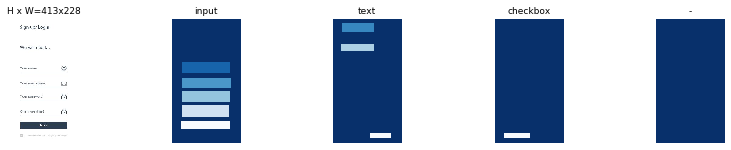

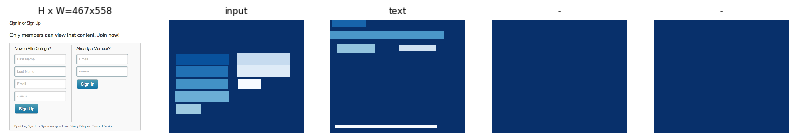

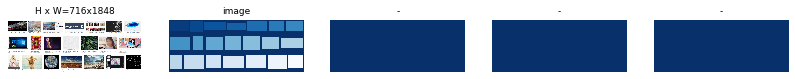

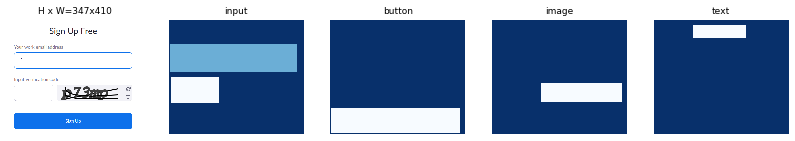

In [9]:
# Load and display random samples
image_ids = np.random.choice(dataset_train.image_ids, 4)
for image_id in image_ids:
    image = dataset_train.load_image(image_id)
    mask, class_ids = dataset_train.load_mask(image_id)
    visualize.display_top_masks(image, mask, class_ids, dataset_train.class_names)

## Create Model

In [10]:
# Create model in training mode
model = modellib.MaskRCNN(mode="training", config=config,
                          model_dir=MODEL_DIR)

W0806 11:36:41.392848 140049151967424 deprecation_wrapper.py:119] From /home/user/Desktop/Projects/adevi_cnn3/adevi_cnn3venv/lib/python3.6/site-packages/keras/backend/tensorflow_backend.py:517: The name tf.placeholder is deprecated. Please use tf.compat.v1.placeholder instead.

W0806 11:36:41.408796 140049151967424 deprecation_wrapper.py:119] From /home/user/Desktop/Projects/adevi_cnn3/adevi_cnn3venv/lib/python3.6/site-packages/keras/backend/tensorflow_backend.py:74: The name tf.get_default_graph is deprecated. Please use tf.compat.v1.get_default_graph instead.

W0806 11:36:41.432518 140049151967424 deprecation_wrapper.py:119] From /home/user/Desktop/Projects/adevi_cnn3/adevi_cnn3venv/lib/python3.6/site-packages/keras/backend/tensorflow_backend.py:4138: The name tf.random_uniform is deprecated. Please use tf.random.uniform instead.

W0806 11:36:41.454738 140049151967424 deprecation_wrapper.py:119] From /home/user/Desktop/Projects/adevi_cnn3/adevi_cnn3venv/lib/python3.6/site-packages/ke

In [11]:
# Which weights to start with?
init_with = "coco"  # imagenet, coco, or last

if init_with == "imagenet":
    model.load_weights(model.get_imagenet_weights(), by_name=True)
elif init_with == "coco":
    # Load weights trained on MS COCO, but skip layers that
    # are different due to the different number of classes
    # See README for instructions to download the COCO weights
    model.load_weights(COCO_MODEL_PATH, by_name=True,
                       exclude=["mrcnn_class_logits", "mrcnn_bbox_fc", 
                                "mrcnn_bbox", "mrcnn_mask"])
elif init_with == "last":
    # Load the last model you trained and continue training
    model.load_weights(model.find_last(), by_name=True)

## Training

Train in two stages:
1. Only the heads. Here we're freezing all the backbone layers and training only the randomly initialized layers (i.e. the ones that we didn't use pre-trained weights from MS COCO). To train only the head layers, pass `layers='heads'` to the `train()` function.

2. Fine-tune all layers. For this simple example it's not necessary, but we're including it to show the process. Simply pass `layers="all` to train all layers.

In [12]:
# Train the head branches
# Passing layers="heads" freezes all layers except the head
# layers. You can also pass a regular expression to select
# which layers to train by name pattern.
model.train(dataset_train, dataset_val, 
            learning_rate=config.LEARNING_RATE, 
            epochs=4, 
            layers='heads')


Starting at epoch 0. LR=0.001

Checkpoint Path: /home/user/Desktop/Projects/adevi_cnn3/mask_rcnn/mask_rcnn/logs/form_login20190806T1136/mask_rcnn_form_login_{epoch:04d}.h5
Selecting layers to train
fpn_c5p5               (Conv2D)
fpn_c4p4               (Conv2D)
fpn_c3p3               (Conv2D)
fpn_c2p2               (Conv2D)
fpn_p5                 (Conv2D)
fpn_p2                 (Conv2D)
fpn_p3                 (Conv2D)
fpn_p4                 (Conv2D)
In model:  rpn_model
    rpn_conv_shared        (Conv2D)
    rpn_class_raw          (Conv2D)
    rpn_bbox_pred          (Conv2D)
mrcnn_mask_conv1       (TimeDistributed)
mrcnn_mask_bn1         (TimeDistributed)
mrcnn_mask_conv2       (TimeDistributed)
mrcnn_mask_bn2         (TimeDistributed)
mrcnn_class_conv1      (TimeDistributed)
mrcnn_class_bn1        (TimeDistributed)
mrcnn_mask_conv3       (TimeDistributed)
mrcnn_mask_bn3         (TimeDistributed)
mrcnn_class_conv2      (TimeDistributed)
mrcnn_class_bn2        (TimeDistributed)
mrcnn_

W0806 11:36:52.793559 140049151967424 deprecation_wrapper.py:119] From /home/user/Desktop/Projects/adevi_cnn3/adevi_cnn3venv/lib/python3.6/site-packages/keras/optimizers.py:790: The name tf.train.Optimizer is deprecated. Please use tf.compat.v1.train.Optimizer instead.

/home/user/Desktop/Projects/adevi_cnn3/adevi_cnn3venv/lib/python3.6/site-packages/tensorflow/python/ops/gradients_util.py:93: UserWarning: Converting sparse IndexedSlices to a dense Tensor of unknown shape. This may consume a large amount of memory.
  "Converting sparse IndexedSlices to a dense Tensor of unknown shape. "
/home/user/Desktop/Projects/adevi_cnn3/adevi_cnn3venv/lib/python3.6/site-packages/tensorflow/python/ops/gradients_util.py:93: UserWarning: Converting sparse IndexedSlices to a dense Tensor of unknown shape. This may consume a large amount of memory.
  "Converting sparse IndexedSlices to a dense Tensor of unknown shape. "
/home/user/Desktop/Projects/adevi_cnn3/adevi_cnn3venv/lib/python3.6/site-packages/t

Epoch 1/4


Process ForkPoolWorker-3:
Process ForkPoolWorker-8:
Process ForkPoolWorker-7:
Traceback (most recent call last):
Process ForkPoolWorker-1:
Traceback (most recent call last):
Traceback (most recent call last):
Process ForkPoolWorker-4:
  File "/home/user/.pyenv/versions/3.6.6/lib/python3.6/multiprocessing/process.py", line 258, in _bootstrap
    self.run()
  File "/home/user/.pyenv/versions/3.6.6/lib/python3.6/multiprocessing/process.py", line 258, in _bootstrap
    self.run()
Traceback (most recent call last):
  File "/home/user/.pyenv/versions/3.6.6/lib/python3.6/multiprocessing/process.py", line 258, in _bootstrap
    self.run()
  File "/home/user/.pyenv/versions/3.6.6/lib/python3.6/multiprocessing/process.py", line 93, in run
    self._target(*self._args, **self._kwargs)
  File "/home/user/.pyenv/versions/3.6.6/lib/python3.6/multiprocessing/process.py", line 93, in run
    self._target(*self._args, **self._kwargs)
Traceback (most recent call last):
  File "/home/user/.pyenv/versions

  File "/home/user/Desktop/Projects/adevi_cnn3/adevi_cnn3venv/lib/python3.6/site-packages/skimage/_shared/utils.py", line 239, in convert_to_float
    image = image.astype(np.double)
  File "/home/user/Desktop/Projects/adevi_cnn3/mask_rcnn/mrcnn/model.py", line 1709, in data_generator
    use_mini_mask=config.USE_MINI_MASK)
  File "/home/user/Desktop/Projects/adevi_cnn3/mask_rcnn/mrcnn/utils.py", line 903, in resize
    anti_aliasing_sigma=anti_aliasing_sigma)
KeyboardInterrupt
KeyboardInterrupt
  File "/home/user/.pyenv/versions/3.6.6/lib/python3.6/multiprocessing/process.py", line 258, in _bootstrap
    self.run()
  File "/home/user/Desktop/Projects/adevi_cnn3/adevi_cnn3venv/lib/python3.6/site-packages/skimage/_shared/utils.py", line 239, in convert_to_float
    image = image.astype(np.double)
  File "/home/user/.pyenv/versions/3.6.6/lib/python3.6/multiprocessing/process.py", line 93, in run
    self._target(*self._args, **self._kwargs)
  File "/home/user/Desktop/Projects/adevi_cnn3/

KeyboardInterrupt: 

In [ ]:
!ls

In [ ]:
model_path = os.path.join(MODEL_DIR, "mask_rcnn_shapes.h5")
model.keras_model.save_weights(model_path)

In [ ]:
# Fine tune all layers
# Passing layers="all" trains all layers. You can also 
# pass a regular expression to select which layers to
# train by name pattern.
model.train(dataset_train, dataset_val, 
            learning_rate=config.LEARNING_RATE / 10,
            epochs=500, 
            layers="all")

In [ ]:
model.train(dataset_train, dataset_val, 
            learning_rate=config.LEARNING_RATE / 10,
            epochs=800, 
            layers="all")

In [ ]:
model_path = os.path.join(MODEL_DIR, "mask_rcnn_shapes.h5")
model.keras_model.save_weights(model_path)

In [ ]:
# Fine tune all layers
# Passing layers="all" trains all layers. You can also 
# pass a regular expression to select which layers to
# train by name pattern.
model.load_weights(model_path, by_name=True)
model.train(dataset_train, dataset_val, 
            learning_rate=config.LEARNING_RATE / 10,
            epochs=3, 
            layers="all")

In [ ]:
# Save weights
# Typically not needed because callbacks save after every epoch
# Uncomment to save manually
 model_path = os.path.join(MODEL_DIR, "mask_rcnn_shapes.h5")
 model.keras_model.save_weights(model_path)

## Detection

In [20]:
class InferenceConfig(LoginConfig):
    GPU_COUNT = 1
    IMAGES_PER_GPU = 1

inference_config = InferenceConfig()

# Recreate the model in inference mode
model = modellib.MaskRCNN(mode="inference", 
                          config=inference_config,
                          model_dir=MODEL_DIR)

# Get path to saved weights
# Either set a specific path or find last trained weights
# model_path = os.path.join(ROOT_DIR, ".h5 file name here")
model_path = model.find_last()

# Load trained weights
print("Loading weights from ", model_path)
model.load_weights(model_path, by_name=True)

Loading weights from  /home/user/Desktop/Projects/adevi_cnn3/mask_rcnn/logs/form_login20190806T1127/mask_rcnn_form_login_0662.h5
Re-starting from epoch 662


original_image           shape: (128, 128, 3)         min:    0.00000  max:  255.00000  uint8
image_meta               shape: (20,)                 min:    0.00000  max: 1840.00000  float64
gt_class_id              shape: (20,)                 min:    6.00000  max:    6.00000  int32
gt_bbox                  shape: (20, 4)               min:    1.00000  max:  127.00000  int32
gt_mask                  shape: (128, 128, 20)        min:    0.00000  max:    1.00000  bool


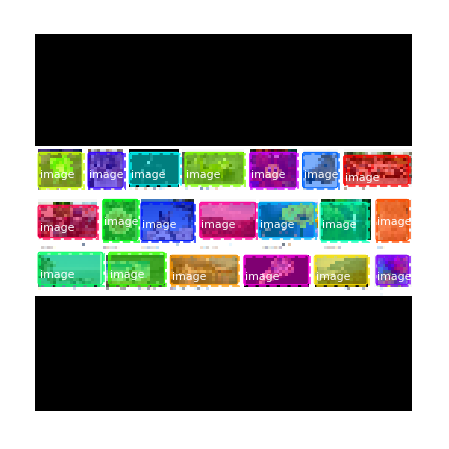

In [33]:
# Test on a random image
image_id = random.choice(dataset_val.image_ids)
original_image, image_meta, gt_class_id, gt_bbox, gt_mask =\
    modellib.load_image_gt(dataset_val, inference_config, 
                           image_id, use_mini_mask=False)

log("original_image", original_image)
log("image_meta", image_meta)
log("gt_class_id", gt_class_id)
log("gt_bbox", gt_bbox)
log("gt_mask", gt_mask)

visualize.display_instances(original_image, gt_bbox, gt_mask, gt_class_id, 
                            dataset_train.class_names, figsize=(8, 8))

Processing 1 images
image                    shape: (128, 128, 3)         min:    0.00000  max:  255.00000  uint8
molded_images            shape: (1, 128, 128, 3)      min: -123.70000  max:  151.10000  float64
image_metas              shape: (1, 20)               min:    0.00000  max:  128.00000  int64
anchors                  shape: (1, 4092, 4)          min:   -0.71267  max:    1.20874  float32


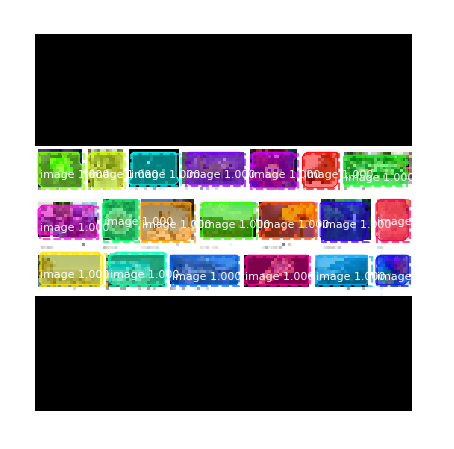

In [34]:
results = model.detect([original_image], verbose=1)

r = results[0]
visualize.display_instances(original_image, r['rois'], r['masks'], r['class_ids'], 
                            dataset_val.class_names, r['scores'], ax=get_ax())

## Evaluation

In [35]:
import math
x1=5
x2=5
[x1*x1,math.sqrt(2)*x1*x2,x2*x2]

[25, 35.35533905932738, 25]

In [36]:
-(65*0)-(11*1)-(31*4)-(72*9)+(30*1)+(21*16)+(4*16)+(15*25)

22

In [37]:
np.dot([21,-22.627387,22],[25,35.355339,35])-110

385.00106193080705

In [38]:
# Compute VOC-Style mAP @ IoU=0.5
# Running on 10 images. Increase for better accuracy.
image_ids = np.random.choice(dataset_val.image_ids, 10)
APs = []
for image_id in image_ids:
    # Load image and ground truth data
    image, image_meta, gt_class_id, gt_bbox, gt_mask =\
        modellib.load_image_gt(dataset_val, inference_config,
                               image_id, use_mini_mask=False)
    molded_images = np.expand_dims(modellib.mold_image(image, inference_config), 0)
    # Run object detection
    results = model.detect([image], verbose=0)
    r = results[0]
    # Compute AP
    AP, precisions, recalls, overlaps =\
        utils.compute_ap(gt_bbox, gt_class_id, gt_mask,
                         r["rois"], r["class_ids"], r["scores"], r['masks'])
    APs.append(AP)
    
print("mAP: ", np.mean(APs))

mAP:  0.9843495965003968
